# c₂ distribution in Cartesian k-space, both materials (draft figure; not yet placed in main2)

c₂(**k**) = the integrand of Eq. (4curv-reduced), ∂θ/∂Q = ∫_BZ c₂ d³k (unit-cube volume in reduced coordinates).
Tr[𝔅𝔅] is invariant under k-dependent unitary rotations of the occupied states, so unlike the Chern–Simons 3-form
density its distribution is physical (for the given Wannier interpolant). Mean of the two endpoint estimates.

* **(a)** MnBi₂Te₄: c₂ on one plane across the k_z axis, (k_x, k_y) Cartesian, from the refined box of the tube k list.
* **(b)** MnBi₂Te₄: fraction of ∂θ/∂Q from k within k⊥ of the k_z axis through Γ (all planes, tube quadrature
  weights), and c₂ against k⊥.
* **(c)** Y₂Ir₂O₇: c₂ on the plane through Γ spanned by b₁, b₂ (Cartesian), clipped to the first Brillouin zone; interpolated
  (periodic cubic spline) from the 10³ mesh of the production pair.
* **(d)** Both: fraction of ∂θ/∂Q contributed by the k points with the largest |c₂|, against the fraction of the zone
  they occupy. A narrow hot spot rises steeply; a spread-out integrand with sign changes wanders and overshoots.

**Data status.** MBT here is mode 3 at Q = 0.01 Å from the conv_thr 1e-10 production tube (214627; swapped in 2026-10-22,
was the provisional 1e-7 pair 214347). Every symmetry mode of both materials: `../analysis/c2_distribution_modes.ipynb`. YIO is production (self-test base, series windows) but only
on the 10³ mesh; a dense plane needs a dedicated run.

In [1]:
# ---- settings
from pathlib import Path
ROOT = Path("/Users/treycole/Repos/axion-phonon")
DATA = ROOT / "data"
MBT_TUBE = DATA / "MnBi2Te4/archive/dtheta_tube_conv1e-10_k8_2026-10-19/mode3_Q0p01"   # klist.npz + chunks/ (1e-10 production tube, half-width 3, m 4, 8 planes)
MBT_WIN = DATA / "MnBi2Te4/archive/base/lda/w90_sp_d_k8_selftest_conv1e-10_214301/MnBi2Te4.win"   # cell
MBT_LABEL = "mode 3 (Te1)"
MBT_PLANE = 0                        # u3 plane index of the map (0: through Γ)
MBT_MAP_HALF = 0.25                  # 1/Å, half-width of map (a)
YIO_C2 = {m: next((DATA / "Y2Ir2O7/phonon/GM2-").glob(f"mode{m}/Q_0.01A/lda/w90_trial02_ampwin10_2026-10-18_*/nk_sweep_tif_shared_ws_selftestbase/nk_10.npz"))
          for m in (1, 2, 3)}
YIO_WIN = DATA / "Y2Ir2O7/base/lda/w90_trial02_selftest_ampwin10_214249/Y2Ir2O7.win"
YIO_LABELS = {1: "Y", 2: "Ir", 3: r"O$_{48f}$"}
YIO_MAP_PATTERN = 2                  # pattern shown in (c)
YIO_GRID = 301                       # points per side of the interpolation grid in (c)
END = "mean"                         # 0: undistorted end, 1: displaced end, "mean"
FIGSIZE = (7.0, 5.8)
FONT_SIZE = 8
SAVE_FIG = ROOT / "paper/figures/c2_distribution.pdf"   # draft; or None
# ---------------

In [2]:
# ---- data
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm, TwoSlopeNorm
from scipy.ndimage import map_coordinates

def cell(win):
    lines = Path(win).read_text().splitlines()
    i = next(j for j, line in enumerate(lines) if line.strip().lower() == "begin unit_cell_cart")
    rows = [line.split() for line in lines[i + 1:i + 5] if line.split() and line.split()[0].lower() not in ("ang", "bohr")][:3]
    A = np.array(rows, float)
    return A, 2 * np.pi * np.linalg.inv(A).T                      # rows a_i (Å), rows b_i (1/Å)

def pick(c2):
    return c2.real.mean(axis=-1) if END == "mean" else c2[..., END].real

# MnBi2Te4: tube k list, chunks, quadrature weights (assemble_tube.py: h² outside the box, (h/M)² inside, / N3)
kl = np.load(MBT_TUBE / "klist.npz")
nk, M, N3 = int(kl["nk"]), int(kl["M"]), int(kl["n3"])
c2_m = np.full(len(kl["k"]), np.nan)
gap_m = np.full(len(kl["k"]), np.nan)
for f in sorted((MBT_TUBE / "chunks").glob("chunk_*")):
    z = np.load(f)
    c2_m[z["idx"]] = pick(z["c2"])
    gap_m[z["idx"]] = z["gap"].mean(axis=-1)
assert not np.isnan(c2_m).any(), "missing chunks"
w_m = np.where(kl["level"] == 0, (1 / nk) ** 2, (1 / nk / M) ** 2) / N3
_, B_m = cell(MBT_WIN)
zhat = B_m.sum(0) / np.linalg.norm(B_m.sum(0))                    # k_z: the tube axis t(b1 + b2 + b3)
k_red = (kl["k"] + 0.5) % 1 - 0.5
images = np.array(np.meshgrid(*[[-1, 0, 1]] * 3, indexing="ij")).reshape(3, -1).T
kc_all = (k_red[:, None, :] + images[None]) @ B_m                  # (N, 27, 3) Cartesian images
perp_all = np.linalg.norm(kc_all - (kc_all @ zhat)[..., None] * zhat, axis=-1)
best = perp_all.argmin(1)
kc_m = kc_all[np.arange(len(best)), best]                          # the image nearest the axis
kperp = perp_all.min(1)
bp = [B_m[j] - (B_m[j] @ zhat) * zhat for j in (0, 1)]                # in-plane parts of b1, b2
sin_ab = np.sqrt(1 - (bp[0] @ bp[1] / np.linalg.norm(bp[0]) / np.linalg.norm(bp[1])) ** 2)
BOX_INRADIUS = (int(kl["half"]) + 0.5) / nk * np.linalg.norm(bp[0]) * sin_ab   # refined rhombus: largest circle inside
print(f"MBT refined region: rhombus in (u1, u2), inradius {BOX_INRADIUS:.3f} 1/Å; max k⊥ {kperp.max():.3f} 1/Å")
dtheta_m = (w_m * c2_m).sum()
print(f"MBT: {len(c2_m)} k, Σw = {w_m.sum():.6f}, ∂θ/∂Q = {dtheta_m:.4f} rad/Å ({MBT_LABEL}); k_z axis {zhat.round(3)}")
order = np.argsort(kperp)
cum_r = np.cumsum((w_m * c2_m)[order]) / dtheta_m
for r in (0.05, 0.1, 0.2):
    print(f"   within k⊥ < {r} 1/Å: {100 * cum_r[np.searchsorted(kperp[order], r) - 1]:.1f}% of ∂θ/∂Q, "
          f"{100 * w_m[kperp < r].sum():.2f}% of the zone")

# Y2Ir2O7: 10³ mesh, k = n / nk in reduced coordinates
c2_y = {m: pick(np.asarray(np.load(f, allow_pickle=True)["c2_density"])) for m, f in YIO_C2.items()}
_, B_y = cell(YIO_WIN)
for m, c in c2_y.items():
    print(f"YIO pattern {m} ({YIO_LABELS[m]}): ∂θ/∂Q = {c.mean():+.6f} rad/Å on {c.shape[0]}³")

MBT refined region: rhombus in (u1, u2), inradius 0.317 1/Å; max k⊥ 0.912 1/Å
MBT: 7928 k, Σw = 1.000000, ∂θ/∂Q = 6.5186 rad/Å (mode 3 (Te1)); k_z axis [0. 0. 1.]
   within k⊥ < 0.05 1/Å: 46.2% of ∂θ/∂Q, 0.32% of the zone
   within k⊥ < 0.1 1/Å: 85.4% of ∂θ/∂Q, 1.34% of the zone
   within k⊥ < 0.2 1/Å: 97.4% of ∂θ/∂Q, 5.15% of the zone
YIO pattern 1 (Y): ∂θ/∂Q = -0.017184 rad/Å on 10³
YIO pattern 2 (Ir): ∂θ/∂Q = +0.054487 rad/Å on 10³
YIO pattern 3 (O$_{48f}$): ∂θ/∂Q = +0.063782 rad/Å on 10³


In [3]:
# ---- YIO plane through Γ spanned by b1, b2 (Cartesian), periodic cubic interpolation, first-BZ mask
e1 = B_y[0] / np.linalg.norm(B_y[0])
e2 = B_y[1] - (B_y[1] @ e1) * e1
e2 /= np.linalg.norm(e2)
normal = np.cross(e1, e2)
print("plane normal (Cartesian):", (normal / np.abs(normal).max()).round(3))
R = 1.05 * np.linalg.norm(B_y, axis=1).max()
s = np.linspace(-R, R, YIO_GRID)
S, T = np.meshgrid(s, s, indexing="xy")
kc = S[..., None] * e1 + T[..., None] * e2
kr = kc @ np.linalg.inv(B_y)                                       # reduced coordinates
G = np.array(np.meshgrid(*[range(-2, 3)] * 3, indexing="ij")).reshape(3, -1).T @ B_y
G = G[np.linalg.norm(G, axis=1) > 1e-9]
inside = np.all(np.einsum("ijk,gk->ijg", kc, G) <= 0.5 * (G ** 2).sum(1), axis=-1)   # |k| <= |k - G|
c = c2_y[YIO_MAP_PATTERN]
n = c.shape[0]
coords = (kr % 1.0 * n).transpose(2, 0, 1)                          # index coordinates of the periodic grid
yio_map = np.where(inside, map_coordinates(c, coords, order=3, mode="grid-wrap"), np.nan)
# high-symmetry points of the fcc zone that lie in this plane
a = np.linalg.norm(cell(YIO_WIN)[0][0]) * np.sqrt(2)              # cubic lattice constant
pts = {r"$\Gamma$": (0, 0, 0), "X": (0, 0, 1), "L": (0.5, 0.5, 0.5), "K": (0.75, 0.75, 0), "U": (0.25, 0.25, 1),
       "W": (0.5, 0, 1)}
from itertools import permutations, product
labels_in_plane = []
for name, p in pts.items():
    for perm in set(permutations(p)):
        for sg in product((1, -1), repeat=3):
            k = 2 * np.pi / a * np.array(perm) * sg
            if abs(k @ normal) < 1e-6 and np.all(np.abs(k @ np.array([e1, e2]).T) <= R):
                labels_in_plane.append((name, k @ e1, k @ e2))
print("cubic a =", round(a, 4), "Å; in-plane points:", sorted({l[0] for l in labels_in_plane}))

plane normal (Cartesian): [1. 1. 0.]
cubic a = 10.19 Å; in-plane points: ['$\\Gamma$', 'K', 'L', 'U', 'X']


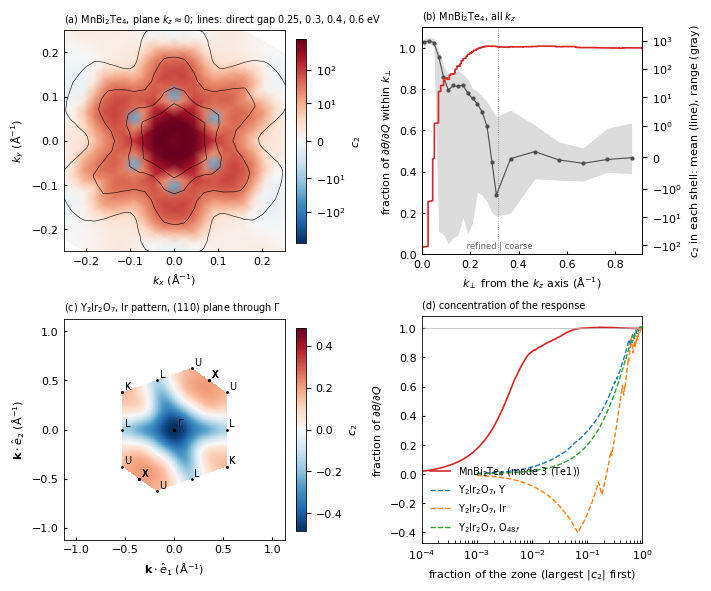

In [4]:
# ---- draw
plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6})
fig, ((ax_a, ax_b), (ax_c, ax_d)) = plt.subplots(2, 2, figsize=FIGSIZE, layout="constrained")

# (a) MBT map on one plane, inside the refined box
sel = (kl["plane"] == MBT_PLANE) & (kl["level"] >= 1)
x, y = kc_m[sel] @ np.array([1, 0, 0]), kc_m[sel] @ np.array([0, 1, 0])
vmax = np.nanmax(np.abs(c2_m[sel]))
im = ax_a.tripcolor(x, y, c2_m[sel], shading="gouraud", cmap="RdBu_r", norm=SymLogNorm(linthresh=10, vmin=-vmax, vmax=vmax))
ax_a.tricontour(x, y, gap_m[sel], levels=[0.25, 0.3, 0.4, 0.6], colors="k", linewidths=0.4)
ax_a.set(xlim=(-MBT_MAP_HALF, MBT_MAP_HALF), ylim=(-MBT_MAP_HALF, MBT_MAP_HALF), aspect="equal",
         xlabel=r"$k_x$ (Å$^{-1}$)", ylabel=r"$k_y$ (Å$^{-1}$)")
fig.colorbar(im, ax=ax_a, label=r"$c_2$", shrink=0.9)
ax_a.set_title("(a) MnBi$_2$Te$_4$, plane $k_z\\approx0$; lines: direct gap 0.25, 0.3, 0.4, 0.6 eV", loc="left", fontsize=FONT_SIZE - 1)

# (b) MBT radial: cumulative fraction, and c2 per k_perp value (each value holds every plane and every
#     symmetry-related in-plane point at that distance: the band is their min-max, the line their median)
ax_b.plot(kperp[order], cum_r, color="C3", lw=1.2, label=r"fraction of $\partial\theta/\partial Q$ within $k_\perp$")
ax_b.axvline(BOX_INRADIUS, color="0.5", lw=0.6, ls=":")
ax_b.text(BOX_INRADIUS, 0.03, " refined | coarse", fontsize=FONT_SIZE - 2, color="0.4", ha="center")
ax_b.set(xlim=(0, kperp.max()), ylim=(0, 1.1), xlabel=r"$k_\perp$ from the $k_z$ axis (Å$^{-1}$)",
         ylabel=r"fraction of $\partial\theta/\partial Q$ within $k_\perp$")
ax_b2 = ax_b.twinx()
edges = np.r_[np.arange(0, BOX_INRADIUS, 0.02), np.arange(BOX_INRADIUS, kperp.max() + 0.1, 0.1)]   # shells: fine inside the refined region
shell = np.digitize(kperp, edges) - 1
mid, avg, lo, hi = [], [], [], []
for g in np.unique(shell):
    m = shell == g
    mid.append(0.5 * (edges[g] + edges[g + 1])); avg.append((w_m[m] * c2_m[m]).sum() / w_m[m].sum())
    lo.append(c2_m[m].min()); hi.append(c2_m[m].max())
ax_b2.fill_between(mid, lo, hi, color="0.8", alpha=0.7, lw=0)
ax_b2.plot(mid, avg, "o-", color="0.3", lw=0.8, ms=2)
ax_b2.set_yscale("symlog", linthresh=1)
ax_b2.set_ylabel(r"$c_2$ in each shell: mean (line), range (gray)")
ax_b.set_zorder(ax_b2.get_zorder() + 1); ax_b.patch.set_visible(False)
ax_b.set_title("(b) MnBi$_2$Te$_4$, all $k_z$", loc="left", fontsize=FONT_SIZE - 1)

# (c) YIO plane map
v = np.nanmax(np.abs(yio_map))
im = ax_c.pcolormesh(S, T, yio_map, cmap="RdBu_r", norm=TwoSlopeNorm(0, -v, v), shading="auto")
for name, u, w in labels_in_plane:
    ax_c.plot(u, w, "k.", ms=2)
    ax_c.annotate(name, (u, w), xytext=(2, 2), textcoords="offset points", fontsize=FONT_SIZE - 1)
ax_c.set(aspect="equal", xlabel=r"$\mathbf{k}\cdot\hat e_1$ (Å$^{-1}$)", ylabel=r"$\mathbf{k}\cdot\hat e_2$ (Å$^{-1}$)")
fig.colorbar(im, ax=ax_c, label=r"$c_2$", shrink=0.9)
ax_c.set_title(f"(c) Y$_2$Ir$_2$O$_7$, {YIO_LABELS[YIO_MAP_PATTERN]} pattern, (110) plane through $\\Gamma$", loc="left", fontsize=FONT_SIZE - 1)

# (d) concentration curves
o = np.argsort(-np.abs(c2_m))
ax_d.plot(np.cumsum(w_m[o]), np.cumsum((w_m * c2_m)[o]) / dtheta_m, color="C3", lw=1.2, label=f"MnBi$_2$Te$_4$ ({MBT_LABEL})")
for m, c in c2_y.items():
    f = c.ravel()[np.argsort(-np.abs(c.ravel()))]          # largest |c2| first
    ax_d.plot(np.arange(1, f.size + 1) / f.size, np.cumsum(f) / f.sum(), lw=1, ls="--",
              label=f"Y$_2$Ir$_2$O$_7$, {YIO_LABELS[m]}")
ax_d.set(xscale="log", xlim=(1e-4, 1), xlabel="fraction of the zone (largest $|c_2|$ first)",
         ylabel=r"fraction of $\partial\theta/\partial Q$")
ax_d.axhline(1, color="0.7", lw=0.5)
ax_d.legend(fontsize=FONT_SIZE - 1, frameon=False, loc="lower left")
ax_d.set_title("(d) concentration of the response", loc="left", fontsize=FONT_SIZE - 1)
for ax in (ax_a, ax_b, ax_c, ax_d):
    ax.tick_params(direction="in", length=2, which="both")
if SAVE_FIG:
    fig.savefig(SAVE_FIG)
    fig.savefig(SAVE_FIG.with_suffix(".png"), dpi=300)
plt.show()
plt.rcdefaults()